In [1]:
# Rucno importovanje ssp modula:
import sys
sys.path.insert(0, '/home/emir/Faks/SIS2/Knjiga_SIS2/Prilozi/SIS2_Kodovi/')
import ssp

# Importovanje ostalih biblioteka:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import hist

# Podesavanje prikaza za knjigu:
ssp.FORMATIRANJE_PRIKAZA = "BOOK"
ssp.REZOLUCIJA = "LOW"

# Podesavanje prikaza za rad studenata:
# ssp.FORMATIRANJE_PRIKAZA = "JUPYTER"
# ssp.REZOLUCIJA = "LOW"

In [2]:
#Programski kod 6.1

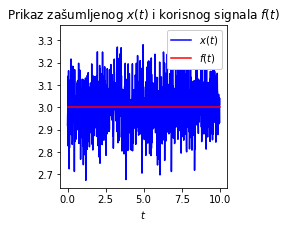

In [3]:
N = 1000
step = 10/N
t = np.arange(0, 10, step)

# Stacionarni proces   
f = 3*np.ones(np.shape(t))

# Shum
NL = 0.1
n = NL*np.random.normal(0,1, N)

# Signal sa shumom
x = f + n

# Prikaz x(t) i f(t)
ssp.slprom1D.grafik(t, x, t, f, 
                    naslov = "Prikaz zašumljenog $x(t)$ i korisnog signala $f(t)$",
                    legenda = ['$x(t)$', '$f(t)$'])

In [4]:
#Programski kod 6.2

In [5]:
Pf = np.sum(f**2)*step  # Snaga signala
print("Snaga signala Pf: {:.2f}".format(Pf))

Pn = np.sum(n**2)*step  # Snaga šuma
print("Snaga šuma Pn: {:.2f}".format(Pn))

SNR = Pf/Pn  # SNR
print("Odnos signal - šum: {:.2f}".format(SNR))

# Proračun u dB

Pf_dB = 10*np.log10(Pf)
print("Snaga signala izražena u dB: {:.2f}".format(Pf_dB))

Pn_dB = 10*np.log10(Pn)
print("Snaga šuma izražena u dB: {:.2f}".format(Pn_dB))

SNR_dB = 10*np.log10(SNR)
print("Odnos signal - šum izražen u dB: {:.2f}".format(SNR_dB))

Snaga signala Pf: 90.00
Snaga šuma Pn: 0.11
Odnos signal - šum: 824.08
Snaga signala izražena u dB: 19.54
Snaga šuma izražena u dB: -9.62
Odnos signal - šum izražen u dB: 29.16


In [6]:
#Programski kod 6.3

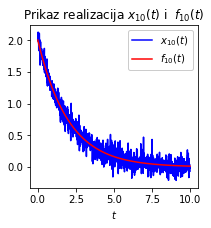

In [7]:
N = 1000
M = 500
step = 10/N

t = np.arange(0, 10, step)
slproc_x = np.empty((M, N))
f = np.empty((M, N))
n = np.empty((M, N))

NL = 0.1  #"intenzitet" šuma

for k in range(M):
    f[k, :] = 2*np.exp(-t/2)
    n[k, :] = NL*np.random.normal(0,1, N)
    x = f[k, :]+n[k, :]
    slproc_x[k, :] = x 

ssp.slprom1D.grafik(t,slproc_x[10,:],t,f[10,:], 
                    naslov = "Prikaz realizacija $x_{10}(t)$ i  $f_{10}(t)$",
                    legenda = ['$x_{10}(t)$', '$f_{10}(t)$'])

In [8]:
#Programski kod 6.4

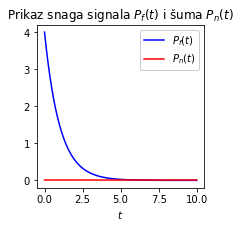

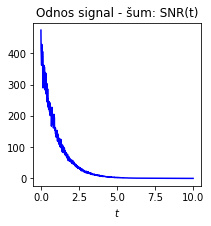

In [9]:
# Određivanje očekivane srednjekvadratne vrijednosti procesa
Pf = np.empty(N)
for i in range(N):
    Pf[i] = np.mean((f[:,i])**2)
    
Pn = np.empty(N)
for i in range(N):
    Pn[i] = np.mean((n[:,i])**2)
    
#Prikaz snage signala i šuma
ssp.slprom1D.grafik(t, Pf, t, Pn, 
                    naslov = "Prikaz snaga signala $P_f(t)$ i šuma $P_n(t)$",
                    legenda = ['$P_f(t)$', '$P_n(t)$'])

SNR = Pf/Pn

#Prikaz SNR
ssp.slprom1D.grafik(t, SNR, naslov = "Odnos signal - šum: SNR(t)")

In [10]:
#Programski kod 6.5

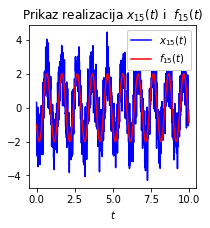

In [11]:
N = 1000
M = 2000
step = 10/N

t = np.arange(0, 10, step)
slproc_x = np.empty((M, N))
f = np.empty((M, N))
n = np.empty((M, N))
theta = np.random.uniform(0,2*np.pi,M)

a = 2
omega0 = 2*np.pi

for k in range(M):
    f[k,:] = a*np.cos(omega0*t+theta[k])
    n[k,:] = np.random.normal(0,1, N)
    x = f[k,:]+n[k,:]
    slproc_x[k,:] = x 

ssp.slprom1D.grafik(t,slproc_x[15,:],t,f[15,:], 
                    naslov = "Prikaz realizacija $x_{15}(t)$ i  $f_{15}(t)$",
                    legenda = ['$x_{15}(t)$', '$f_{15}(t)$'])

In [12]:
#Programski kod 6.6

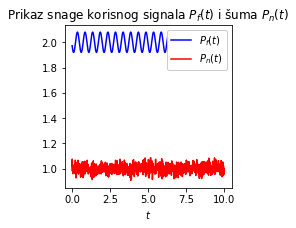

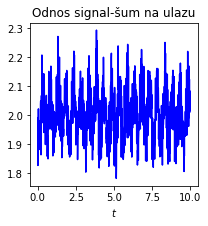

In [13]:
Pf = np.empty(N)
for i in range(N):
    Pf[i] = np.mean((f[:,i])**2)
    
Pn = np.empty(N)
for i in range(N):
    Pn[i] = np.mean((n[:,i])**2)
    
#Crtanje snage signala i šuma
ssp.slprom1D.grafik(t, Pf, t, Pn, 
                    naslov = "Prikaz snage korisnog signala $P_f(t)$ i šuma $P_n(t)$",
                    legenda = ['$P_f(t)$', '$P_n(t)$'])
SNR = Pf/Pn

#Prikaz SNR
ssp.slprom1D.grafik(t, SNR, naslov = "Odnos signal-šum na ulazu")

In [14]:
#Programski kod 6.7

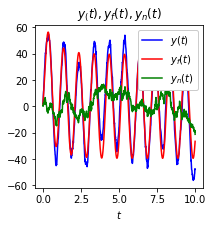

In [15]:
# Propustanje signala kroz sistem
RC = 1/(0.2*omega0)
h = (1/RC)* np.exp(-t/RC)

Y = np.empty((M, N))
Y_f = np.empty((M, N))
Y_n = np.empty((M, N))

for k in range(M):
    y = np.convolve(slproc_x[k,:], h)
    Y[k, :] = y[0:N] 
    yf = np.convolve(f[k,:], h)
    Y_f[k, :] = yf[0:N]
    yn = np.convolve(n[k,:], h)
    Y_n[k, :] = yn[0:N]

Ntest = 88    
#Crtanje izlaznog signala (slučajnog procesa)
ssp.slprom1D.grafik(t, Y[Ntest,:], t, Y_f[Ntest, :], t,Y_n[Ntest,:], 
                     naslov = '$y_(t), y_f(t), y_n(t)$',
                     legenda = ['$y(t)$', '$y_f(t)$', '$y_n(t)$'])

In [16]:
#Programski kod 6.8

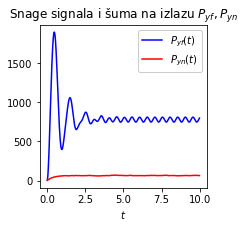

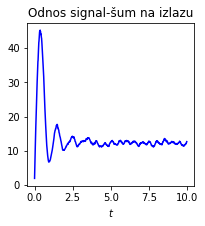

In [17]:
#Određivanje očekivane srednjekvadratne vrijednosti procesa
Pyf = np.empty(N)
for i in range(N):
    Pyf[i] = np.mean((Y_f[:, i])**2)
    
Pyn = np.empty(N)
for i in range(N):
    Pyn[i] = np.mean((Y_n[:, i])**2)
    
#Crtanje snage signala i šuma
ssp.slprom1D.grafik(t, Pyf, t, Pyn, 
                    naslov = "Snage signala i šuma na izlazu $P_{yf}, P_{yn}$",
                    legenda = ['$P_{yf}(t)$', '$P_{yn}(t)$'])

SNRout = Pyf/Pyn

#Prikaz SNR
ssp.slprom1D.grafik(t, SNRout, naslov = "Odnos signal-šum na izlazu")

In [18]:
#Programski kod 6.9

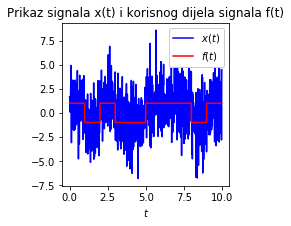

In [19]:
N=1000

step = 10/N

t = np.arange(0, 10, step)
kodovi = np.array([1, -1, 1, -1, -1, 1, 1, 1, -1, 1])

f = np.ones(np.shape(t))

for k in range(10):
    f[int(k*N/10):int((k+1)*N/10)] = kodovi[k]

n = np.random.normal(0,2,N)

x = f + n

#Crtanje signala
ssp.slprom1D.grafik(t, x, t, f, 
                    naslov = "Prikaz signala x(t) i korisnog dijela signala f(t)",
                    legenda = ['$x(t)$', '$f(t)$'])

In [20]:
#Programski kod 6.10

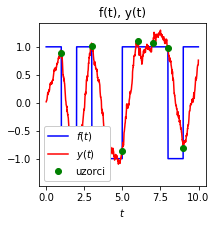

Originalni diskretni signal:   [ True False  True False False  True  True  True False]
Detektovani diskretni signal:  [ True False  True False False  True  True  True False]


In [21]:
#Formiranje prilagođenog filtera konvolucijom:
h = np.ones( np.shape (np.arange(0,1,step)))
y = step*np.convolve(x,h)[0:N]

#sempliranje:
tsempl = t[np.arange(int(N/10),N,int(N/10))]
ysempl = y[np.arange(int(N/10),N,int(N/10))]

ssp.slprom1D.grafik(t, f, t, y, tsempl, ysempl, 
                    stil3 ='go', 
                    naslov = 'f(t), y(t)',
                    legenda = ['$f(t)$', '$y(t)$','uzorci'],
                    lokacija_lgd = 'lower left')

#Usporedba:
print("Originalni diskretni signal:  ",kodovi[0:9]>0)
print("Detektovani diskretni signal: ", ysempl>0)

In [22]:
#Programski kod 6.11

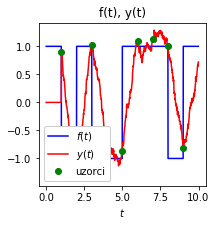

Originalni diskretni signal:   [ True False  True False False  True  True  True False]
Detektovani diskretni signal:  [ True False  True False False  True  True  True False]


In [23]:
#Formiranje prilagođenog filtera - Integrate and dump:
y = np.zeros(np.shape(t))
y_novo = np.zeros(np.shape(t))

T = int(N/10)

for i in np.arange(T, N, 1):
    y[i] = step*np.sum(x[i-T:i+1])
    
    
#sempliranje:
tsempl = t[np.arange(int(N/10), N, int(N/10))]
ysempl = y[np.arange(int(N/10), N, int(N/10))]
    
#Crtanje signala
ssp.slprom1D.grafik(t, f, t, y, tsempl, ysempl, 
                    stil3 = 'go', 
                    naslov = 'f(t), y(t)',
                    legenda = ['$f(t)$', '$y(t)$','uzorci'],
                    lokacija_lgd = 'lower left')

#Usporedba:
print("Originalni diskretni signal:  ",kodovi[0:9]>0)
print("Detektovani diskretni signal: ", ysempl>0)